# 02 · Pertanyaan bisnis: omzet harian dan mingguan

> **DATA DUMMY.** Seluruh angka di notebook ini berasal dari `data/dummy/*_dummy.csv` buatan
> `data/dummy/generate_orders.py` (seed 42), bukan pesanan asli.

Aturan (data dictionary v1.3 bagian 18, `docs/data_limitation_log.md`):

- **Omzet** = nilai item `qty × (unit_price + Σ extra_price opsi)`, hanya pesanan dengan `status <> 'dibatalkan'`.
- **Ongkir tidak termasuk omzet** (D01). Diskon juga tidak dikurangkan karena hanya tercatat per pesanan.
- **Minggu = Senin–Minggu** berdasarkan `deliveries.delivery_date` (D02). Item menempel ke satu pengiriman, jadi tanggalnya diambil dari `order_items.delivery_id`.
- **Agregasi tabel anak dulu** (opsi per item, item per pengiriman) sebelum di-join, supaya tidak terhitung ganda.

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path("../data/dummy")
orders = pd.read_csv(DATA / "orders_dummy.csv")
deliveries = pd.read_csv(DATA / "deliveries_dummy.csv", parse_dates=["delivery_date"])
items = pd.read_csv(DATA / "order_items_dummy.csv")
item_opts = pd.read_csv(DATA / "order_item_options_dummy.csv")
{n: len(df) for n, df in [("orders", orders), ("deliveries", deliveries), ("order_items", items), ("order_item_options", item_opts)]}

{'orders': 180,
 'deliveries': 199,
 'order_items': 413,
 'order_item_options': 663}

## 1. Agregasi tabel anak

Opsi dijumlahkan per item dulu, baru total item dijumlahkan per pengiriman.

In [2]:
# Langkah 1: Σ extra_price per item (satu item bisa punya beberapa opsi)
opsi_per_item = item_opts.groupby("order_item_id", as_index=False)["extra_price"].sum()

# Langkah 2: total item = qty × (unit_price + Σ opsi). Bonus Rp0 ikut dengan nilai 0 (D05).
items2 = items.merge(opsi_per_item, left_on="id", right_on="order_item_id", how="left")
items2["extra_price"] = items2["extra_price"].fillna(0).astype(int)
items2["total_item"] = items2["qty"] * (items2["unit_price"] + items2["extra_price"])
assert len(items2) == len(items), "join opsi tidak boleh menambah baris item"

# Langkah 3: Σ total item per pengiriman
omzet_per_kirim = items2.groupby("delivery_id", as_index=False)["total_item"].sum()
omzet_per_kirim.head()

,delivery_id,total_item
0,1,35000
1,2,87000
2,3,27000
3,4,175000
4,5,191000


## 2. Join ke pengiriman dan pesanan, buang yang dibatalkan

In [3]:
kirim = (deliveries[["id", "order_id", "delivery_date", "shipping_fee"]]
         .merge(omzet_per_kirim, left_on="id", right_on="delivery_id", how="left")
         .merge(orders[["id", "status"]], left_on="order_id", right_on="id", suffixes=("", "_order")))
kirim["total_item"] = kirim["total_item"].fillna(0).astype(int)
assert len(kirim) == len(deliveries), "satu baris per pengiriman"

kirim_valid = kirim[kirim["status"] != "dibatalkan"]
print(f"Pengiriman: {len(kirim)}, setelah buang pesanan dibatalkan: {len(kirim_valid)}")

Pengiriman: 199, setelah buang pesanan dibatalkan: 171


## 3. Omzet harian

Ongkir ditampilkan di kolom terpisah sebagai informasi, **tidak** dijumlahkan ke omzet.

In [4]:
harian = (kirim_valid.groupby("delivery_date")
          .agg(omzet=("total_item", "sum"), ongkir=("shipping_fee", "sum"),
               pesanan=("order_id", "nunique"))
          .reset_index())
harian.tail(10)

,delivery_date,omzet,ongkir,pesanan
64,2026-11-13,629000,30000,3
65,2026-11-14,321000,0,1
66,2026-11-15,100000,20000,1
67,2026-11-16,440000,20000,3
68,2026-11-17,397000,0,2
69,2026-11-18,308000,40000,3
70,2026-11-19,297000,10000,2
71,2026-11-20,314000,20000,3
72,2026-11-21,108000,0,1
73,2026-11-22,87000,20000,1


## 4. Omzet mingguan (Senin–Minggu)

Data dummy dipotong 15 Nov 2026 20.00 WIB. Minggu 16–22 Nov berisi pesanan yang **sudah terjadwal tetapi belum dikirim**; omzetnya bisa berubah bila ada pembatalan.

In [5]:
kirim_valid = kirim_valid.assign(
    minggu_mulai=kirim_valid["delivery_date"] - pd.to_timedelta(kirim_valid["delivery_date"].dt.day_of_week, unit="D"))
mingguan = (kirim_valid.groupby("minggu_mulai")
            .agg(omzet=("total_item", "sum"), ongkir=("shipping_fee", "sum"),
                 pesanan=("order_id", "nunique"))
            .reset_index())
mingguan["minggu_selesai"] = mingguan["minggu_mulai"] + pd.Timedelta(days=6)
assert (mingguan["minggu_mulai"].dt.day_of_week == 0).all(), "minggu harus mulai Senin"
mingguan[["minggu_mulai", "minggu_selesai", "omzet", "ongkir", "pesanan"]]

,minggu_mulai,minggu_selesai,omzet,ongkir,pesanan
0,2026-08-31,2026-09-06,928000,10000,4
1,2026-09-07,2026-09-13,1304000,60000,9
2,2026-09-14,2026-09-20,949000,85000,10
3,2026-09-21,2026-09-27,1361000,120000,10
4,2026-09-28,2026-10-04,2590000,180000,15
5,2026-10-05,2026-10-11,1582000,135000,11
6,2026-10-12,2026-10-18,5408000,260000,23
7,2026-10-19,2026-10-25,3881000,230000,23
8,2026-10-26,2026-11-01,2217000,120000,14
9,2026-11-02,2026-11-08,3372000,205000,16


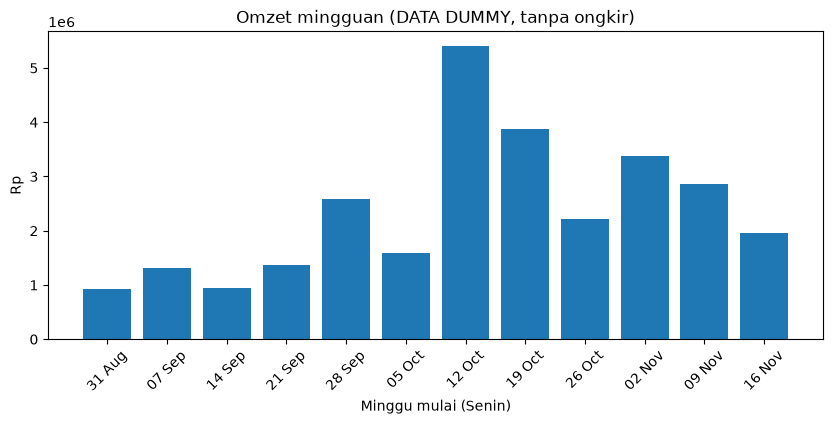

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(mingguan["minggu_mulai"].dt.strftime("%d %b"), mingguan["omzet"])
ax.set_title("Omzet mingguan (DATA DUMMY, tanpa ongkir)")
ax.set_xlabel("Minggu mulai (Senin)"); ax.set_ylabel("Rp")
ax.tick_params(axis="x", rotation=45);

## 5. Cek ketepatan

1. Total omzet harian = mingguan = hitungan langsung dari item pesanan tidak dibatalkan.
2. Contoh hitung ganda: kalau `order_items`, `order_item_options`, dan `deliveries` di-join mentah sebelum agregasi, angka `unit_price × qty` terulang sebanyak jumlah opsi.

In [7]:
valid_ids = orders.loc[orders["status"] != "dibatalkan", "id"]
langsung = items2.loc[items2["order_id"].isin(valid_ids), "total_item"].sum()
assert harian["omzet"].sum() == mingguan["omzet"].sum() == langsung
print(f"Total omzet (dummy): Rp{langsung:,.0f}".replace(",", "."))

# Contoh SALAH: join mentah lalu jumlahkan
salah = items.merge(item_opts, left_on="id", right_on="order_item_id", how="left")
salah = salah[salah["order_id"].isin(valid_ids)]
salah_total = (salah["qty"] * salah["unit_price"]).sum() + (salah["qty"] * salah["extra_price"].fillna(0)).sum()
print(f"Join mentah (salah): Rp{salah_total:,.0f}".replace(",", ".") + f"  → lebih {salah_total / langsung - 1:.0%}")

Total omzet (dummy): Rp28.407.000
Join mentah (salah): Rp46.421.000  → lebih 63%
